# NII dinámico, ganancias en riesgo y EVaR con escenarios de Hull-White y Nelson-Siegel dinámico

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 a 03 de este tema
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este cuaderno puedes:

- ajustar una curva Nelson-Siegel y una Svensson a las tasas cero de una fecha, leer sus parámetros y errores, y decir qué son los factores del Nelson-Siegel dinámico;
- proyectar el margen neto de intereses (NII) mensual de un balance a 12 meses con balance constante, con partidas que reprecian en momentos distintos y con un beta de depósitos;
- generar escenarios de tasa corta de Hull-White de un factor y convertirlos en distribuciones de NII y de EVE, y leer las ganancias en riesgo (EaR) y el valor económico en riesgo (EVaR) con el error de Monte Carlo del cuantil;
- explicar por qué una EaR medida contra una base plana puede salir negativa;
- comparar cada recálculo con el valor versionado, nombrando la versión del motor que lo calculó.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.irrbb import curves, eve_nii, shocks, simulation, slotting
from riskvalidation.validation import irrbb as rv_irrbb

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Los datos son el caso C14, el riesgo de tasa de interés en el libro de banca (IRRBB) del banco que quebró en marzo de 2023, tal como Contraste lo versiona: los reportes de condición de la FDIC (FDIC BankFind financials, https://api.fdic.gov/banks/financials) y la curva a la par del Tesoro de EE. UU. (https://home.treasury.gov/resource-center/data-chart-center/interest-rates), fuentes de dominio público de la clase de licencia `mirror-allowed`. El banco es **real en agregado y sintético en comportamiento**, así que los plazos de reprecio, el beta de depósitos y la reversión a la media de Hull-White los declara o los ajusta Contraste y quedan rotulados en el documento. El dinero está en miles de USD, las tasas son decimales con capitalización continua, y una EaR, EVaR o delta NII positivo es una pérdida.

- **Archivos que se leen:** `data/derived/C14/vd-2022-q2.json` (`outputs.curve`, `dynamic_nii`, `ear_evar`, `balance_sheet`; `impact`), `vd-2021-q4.json` (`outputs.out_of_sample`, `curve`; `tests`) y `vd-2022-q4.json` (`outputs.curve`).
- **No están en el repositorio:** el historial trimestral del costo de los depósitos y de la curva del Tesoro, que el pipeline lee de la raíz de datos. Donde el método necesita un historial de factores (Paso 2), el cuaderno construye uno **construido y con semilla** y lo dice.

La celda siguiente carga los tres documentos.

In [2]:
# Cargar las tres fechas de valoración (el cuaderno está tres carpetas bajo la raíz del repositorio) y los 19 puntos medios
ROOT = Path("../../..").resolve()
docs = {q: json.loads((ROOT / "data" / "derived" / "C14" / f"vd-{q.lower()}.json").read_text(encoding="utf-8")) for q in ("2021-Q4", "2022-Q2", "2022-Q4")}
out = docs["2022-Q2"]["outputs"]
MID = slotting.bucket_grid().midpoints
LANG = "es"  # los campos bilingües de los documentos se leen en este idioma
# Nombres en este idioma de los valores propios del documento (los identificadores del archivo quedan como están)
NAME = {"base": "base", "parallel-up": "paralelo al alza", "parallel-down": "paralelo a la baja", "asset": "activo",
        "liability": "pasivo", True: "sí", False: "no"}
for q, d in docs.items():
    print(q, d["outputs"]["valuation_date"], "| calculado por riskvalidation", d["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)

2021-Q4 2021-12-31 | calculado por riskvalidation 0.8.1 | instalado 0.8.1
2022-Q2 2022-06-30 | calculado por riskvalidation 0.8.1 | instalado 0.8.1
2022-Q4 2022-12-31 | calculado por riskvalidation 0.8.1 | instalado 0.8.1


## Método

El método tiene cinco pasos: (1) ajustar curvas paramétricas, (2) los factores del Nelson-Siegel dinámico y su pronóstico, (3) el NII mensual del balance, (4) los escenarios de Hull-White y las distribuciones de NII y de EVE, (5) la verificación fuera de muestra de la proyección.

### Paso 1: Nelson-Siegel y Svensson

Una curva paramétrica describe toda la curva de rendimientos con pocos números. La curva de Nelson-Siegel da el rendimiento al plazo $m$ con cuatro parámetros, un nivel, una pendiente, una curvatura y un decaimiento $\tau$ (Nelson y Siegel, 1987, https://doi.org/10.1086/296409; dossier 05, D.5):

$$y(m) = \beta_0 + \beta_1\, \frac{1 - e^{-m/\tau}}{m/\tau} + \beta_2 \left( \frac{1 - e^{-m/\tau}}{m/\tau} - e^{-m/\tau} \right)$$

Svensson agrega una segunda joroba, $\beta_3 \left( \frac{1 - e^{-m/\tau_2}}{m/\tau_2} - e^{-m/\tau_2} \right)$ (Svensson, 1994, https://doi.org/10.3386/w4871). Para un $\tau$ fijo la curva es lineal en los betas, así que `fit_nelson_siegel` del motor resuelve mínimos cuadrados para cada $\tau$ de una grilla (0,25 a 10 años en pasos de 0,25) y se queda con el mejor; `fit_svensson` hace una búsqueda en grilla sobre los dos decaimientos seguida de un pulido acotado, y contiene a Nelson-Siegel, así que su error nunca es mayor. La celda siguiente ajusta ambas a las 12 tasas cero del 2022-06-30 e imprime los parámetros y la raíz del error cuadrático medio en puntos base.

In [3]:
# Ajustar Nelson-Siegel y Svensson a las 12 tasas cero versionadas del 2022-06-30 e imprimir los parámetros y el error
points = out["curve"]["points"]
tenors = np.array([p["tenor_years"] for p in points])
zero = np.array([p["zero_rate"] for p in points])
ns = curves.fit_nelson_siegel(tenors, zero)
sv = curves.fit_svensson(tenors, zero)
print(f"Nelson-Siegel: β0 {ns.beta0:.5f} β1 {ns.beta1:.5f} β2 {ns.beta2:.5f} τ {ns.tau:.2f} | error (pb) {ns.rmse * 1e4:.2f}")
print(f"Svensson:      β0 {sv.beta0:.5f} β1 {sv.beta1:.5f} β2 {sv.beta2:.5f} β3 {sv.beta3:.5f} τ1 {sv.tau1:.3f} τ2 {sv.tau2:.3f} | error (pb) {sv.rmse * 1e4:.2f}")
print("el error de Svensson no es mayor que el de Nelson-Siegel:", NAME[sv.rmse <= ns.rmse], "| τ de Nelson-Siegel en el borde de la grilla (0.25):", NAME[ns.tau == curves.DEFAULT_TAU_GRID[0]])
ns_fit = curves.nelson_siegel_yield(tenors, ns.beta0, ns.beta1, ns.beta2, ns.tau)
sv_fit = curves.svensson_yield(tenors, sv.beta0, sv.beta1, sv.beta2, sv.beta3, sv.tau1, sv.tau2)
print(f"{'plazo (a)':>14s} {'tasa cero':>14s} {'Nelson-Siegel':>14s} {'Svensson':>10s}")
for k in range(len(tenors)):
    print(f"{tenors[k]:14.4f} {zero[k]:14.5f} {ns_fit[k]:14.5f} {sv_fit[k]:10.5f}")

Nelson-Siegel: β0 0.03131 β1 -0.02332 β2 0.00855 τ 0.25 | error (pb) 12.59
Svensson:      β0 0.01526 β1 -0.00569 β2 0.04614 β3 0.05473 τ1 0.608 τ2 11.472 | error (pb) 10.09
el error de Svensson no es mayor que el de Nelson-Siegel: sí | τ de Nelson-Siegel en el borde de la grilla (0.25): sí
     plazo (a)      tasa cero  Nelson-Siegel   Svensson
        0.0833        0.01279        0.01262    0.01302
        0.1667        0.01678        0.01614    0.01595
        0.2500        0.01716        0.01883    0.01842
        0.5000        0.02494        0.02377    0.02371
        1.0000        0.02783        0.02753    0.02844
        2.0000        0.02902        0.02946    0.02963
        3.0000        0.02972        0.03008    0.02909
        5.0000        0.02991        0.03057    0.02913
        7.0000        0.03022        0.03079    0.03001
       10.0000        0.02955        0.03094    0.03136
       20.0000        0.03445        0.03113    0.03282
       30.0000        0.03068        

### Paso 2: Nelson-Siegel dinámico

Diebold y Li (2006, https://doi.org/10.1016/j.jeconom.2005.03.005) fijan el decaimiento y dejan que los tres betas se muevan en el tiempo como un factor de **nivel**, uno de **pendiente** y uno de **curvatura**, cada uno siguiendo un AR(1), lo que da un modelo de pronóstico de curvas completas. Con el decaimiento $\lambda = 0{,}0609$ por mes y plazos $m$ en meses, las cargas de los tres factores son

$$y_t(m) = L_t + S_t\, \frac{1 - e^{-\lambda m}}{\lambda m} + C_t \left( \frac{1 - e^{-\lambda m}}{\lambda m} - e^{-\lambda m} \right), \qquad f_{t+1} = c + \phi\, f_t + \varepsilon_t$$

El artículo dice que el decaimiento se eligió para maximizar la carga de curvatura exactamente a los 30 meses; el motor documenta que el máximo está en 29,446 meses y que el artículo redondea. La celda siguiente lo verifica en una grilla fina con las cargas del propio motor, y luego ajusta los tres factores en cada una de las tres fechas versionadas por mínimos cuadrados sobre los plazos que comparten (`fit_dns_factors`). El nivel debería subir a lo largo del ciclo de alzas de 2022.

In [4]:
# Hallar el máximo de la carga de curvatura en una grilla fina, y luego ajustar los tres factores en las tres fechas sobre los plazos compartidos
fine = np.arange(1.0, 120.0, 0.001)
loadings = curves.dns_loadings(fine)
print("λ =", curves.DIEBOLD_LI_LAMBDA, "| la carga de curvatura tiene su máximo en (meses):", round(float(fine[np.argmax(loadings[:, 2])]), 3))
shared_years = np.array([0.25, 0.5, 1.0, 2.0, 3.0, 5.0, 7.0, 10.0, 20.0, 30.0])
months = np.round(shared_years * 12)
panel = []
for q, d in docs.items():
    by_tenor = {round(p["tenor_years"], 2): p["zero_rate"] for p in d["outputs"]["curve"]["points"]}
    panel.append([by_tenor[round(float(y), 2)] for y in shared_years])
factors = curves.fit_dns_factors(months, np.array(panel))
print(f"{'':8s} {'nivel':>9s} {'pendiente':>11s} {'curvatura':>11s}")
for q, f in zip(docs, factors):
    print(f"{q:8s} {f[0]:9.5f} {f[1]:11.5f} {f[2]:11.5f}")

λ = 0.0609 | la carga de curvatura tiene su máximo en (meses): 29.446
             nivel   pendiente   curvatura
2021-Q4    0.02068    -0.02086    -0.00942
2022-Q2    0.03095    -0.01271     0.01523
2022-Q4    0.03837     0.00875     0.00005


Para pronosticar, el modelo necesita un historial de factores, al menos cuatro fechas. Los documentos versionados traen solo tres fechas y el historial completo del pipeline no está en el repositorio, así que la celda siguiente construye un **historial construido y con semilla** de 48 meses de factores AR(1) alrededor de los valores de 2022-Q2, que no son datos del banco. Llama a `forecast_dns_factors` (un AR(1) ajustado a cada factor por mínimos cuadrados, innovaciones gaussianas independientes de la varianza residual ajustada, trayectorias que parten de la última fila del historial y no usan nada posterior) y a `dns_scenarios` (las mismas trayectorias a través de las cargas hacia rendimientos en plazos elegidos), e imprime la dispersión del nivel a 12 meses y del rendimiento a 10 años.

In [5]:
# Un historial de factores construido y con semilla, el pronóstico de los factores y los rendimientos a 12 meses
rng = np.random.default_rng(42)
center = factors[1]
history = np.zeros((48, 3))
history[0] = center
for t in range(1, 48):
    history[t] = center + 0.9 * (history[t - 1] - center) + rng.normal(0, [0.0015, 0.002, 0.003])
paths = curves.forecast_dns_factors(history, 12, 2000, 42)
print("trayectorias de factores (trayectorias, meses, factores):", paths.shape)
print("nivel en el mes 12: media y percentiles 5 y 95:", np.round([paths[:, -1, 0].mean(), *np.percentile(paths[:, -1, 0], [5, 95])], 5))
yields = simulation.dns_scenarios(history, np.array([12.0, 60.0, 120.0]), 12, 2000, 42)
print("trayectorias de rendimiento (trayectorias, meses, plazos):", yields.shape)
print("rendimiento a 10 años en el mes 12: media y percentiles 5 y 95:", np.round([yields[:, -1, 2].mean(), *np.percentile(yields[:, -1, 2], [5, 95])], 5))
print("las mismas trayectorias: los factores por las cargas son iguales a dns_scenarios:", NAME[bool(np.allclose(paths @ curves.dns_loadings(np.array([12.0, 60.0, 120.0])).T, yields))])

trayectorias de factores (trayectorias, meses, factores): (2000, 12, 3)
nivel en el mes 12: media y percentiles 5 y 95: [0.03122 0.02821 0.03415]
trayectorias de rendimiento (trayectorias, meses, plazos): (2000, 12, 3)
rendimiento a 10 años en el mes 12: media y percentiles 5 y 95: [0.03124 0.02804 0.03442]
las mismas trayectorias: los factores por las cargas son iguales a dns_scenarios: sí


### Paso 3: el NII mensual del balance

El NII dinámico proyecta el margen neto de intereses mes a mes durante 12 meses. Cada partida con interés tiene un saldo, un lado (activo o pasivo), una tasa actual y una regla de reprecio: después de su mes de reprecio $k$ la partida gana $\text{spread} + \beta\, r$, donde $r$ es la tasa corta en el mes de su último reprecio y $\beta$ es el traspaso (1 para un activo indexado al mercado, el beta de depósitos para un depósito). Una partida con $k = 0$ reprecia todos los meses; una con $k \ge 1$ conserva su tasa actual en los meses anteriores a $k$ y luego reprecia en $k, 2k, \dots$. El NII mensual es

$$NII_m = \frac{1}{12} \sum_i \text{lado}_i\ B_i\, (1 + g)^{m/12}\ \text{tasa}_{i,m}$$

con $g$ el crecimiento anual del balance; $g = 0$ es el **balance constante** del estándar (los flujos que vencen y reprecian se reemplazan por otros idénticos, BCBS d368 DIS70.5; dossier 05, D.6). El reporte no da los plazos de reprecio, así que el pipeline los declara: 2 meses para la banda de tres meses o menos, 8 meses para tres a doce meses, más allá del horizonte para el resto (sintéticos, en el documento). La celda siguiente lista las diez partidas de la proyección de 2022-Q2.

In [6]:
# Listar las diez partidas del NII dinámico con su saldo, tasa, spread, beta y mes de reprecio
dyn = out["dynamic_nii"]
items = dyn["items"]
print(dyn["balance_sheet_assumption"]["description"][LANG])
print(f"{'':4s} {'lado':9s} {'saldo':>14s} {'tasa':>8s} {'spread':>8s} {'beta':>6s} {'reprecio (meses)':>20s}")
for it in items:
    print(f"{it['item_id']:4s} {NAME[it['side']]:9s} {it['balance']:14,.0f} {it['rate0']:8.4f} {it['spread']:8.4f} {it['beta']:6.3f} {it['reprice_months']:20d}")

Balance constante: los flujos que vencen o reprecian se reemplazan por otros idénticos. Las partidas sin interés se omiten.
     lado               saldo     tasa   spread   beta     reprecio (meses)
D1   activo        14,808,000   0.0041  -0.0087  1.000                    0
D2   activo        55,065,000   0.0310   0.0182  1.000                    2
D3   activo         3,777,000   0.0310   0.0182  1.000                    8
D4   activo        12,019,000   0.0310   0.0310  0.000                  120
D5   activo            50,000   0.0187   0.0059  1.000                    2
D6   activo           556,000   0.0187   0.0059  1.000                    8
D7   activo       121,338,000   0.0187   0.0187  0.000                  120
D8   pasivo       116,177,000   0.0000   0.0000  0.000                    0
D9   pasivo        73,976,000   0.0027   0.0017  0.075                    0
D10  pasivo         3,703,000   0.0128   0.0000  1.000                    0


La función `simulate_nii` del motor recibe los arreglos de las partidas y una trayectoria de tasa corta de 12 a 36 meses. Los escenarios versionados usan una trayectoria plana: la tasa corta de la fecha (la tasa cero de la segunda banda) más el choque, con piso en cero (200 pb al alza, 200 pb a la baja), mantenida los 12 meses. La celda siguiente reconstruye las tres trayectorias con `apply_floor`, corre `simulate_nii` en cada una y compara el NII mensual y el total con los escenarios versionados. El delta contra la base tiene la pérdida positiva: un número negativo es una ganancia.

In [7]:
# Correr simulate_nii del motor en las tres trayectorias planas y comparar con los escenarios versionados
balance = np.array([it["balance"] for it in items])
side = np.array([1 if it["side"] == "asset" else -1 for it in items])
rate0 = np.array([it["rate0"] for it in items])
spread = np.array([it["spread"] for it in items])
beta = np.array([it["beta"] for it in items])
reset = np.array([it["reprice_months"] for it in items])
r0 = np.array(out["curve"]["zero_rates_at_midpoints"])
r_short = float(r0[1])
floor = out["scenarios"][0]["floor"]
result = {}
for committed in dyn["scenarios"]:
    start = float(shocks.apply_floor(np.array([r_short]), np.array([committed["shock_bp"]]), floor)[0])
    path = np.full(12, start)
    result[committed["scenario"]] = simulation.simulate_nii(balance, side, rate0, spread, beta, reset, path, 0.0)
    same = np.allclose(result[committed["scenario"]].monthly_nii, committed["monthly_nii"]) and np.allclose(path, committed["short_rate_path"])
    print(f"{NAME[committed['scenario']]:16s} tasa corta {start:.5f} | NII 12 meses {result[committed['scenario']].total:14,.0f} | delta contra la base {result['base'].total - result[committed['scenario']].total:14,.0f} | igual al versionado {NAME[bool(same)]}")

base             tasa corta 0.01279 | NII 12 meses      4,297,741 | delta contra la base              0 | igual al versionado sí
paralelo al alza tasa corta 0.03279 | NII 12 meses      5,356,610 | delta contra la base     -1,058,869 | igual al versionado sí
paralelo a la baja tasa corta 0.00000 | NII 12 meses      3,620,426 | delta contra la base        677,315 | igual al versionado sí


La misma función acepta el crecimiento anual del balance. Un balance que crece escala cada mes por $(1 + g)^{m/12}$, así que con $g = 5$ por ciento el NII de los 12 meses es mayor que con balance constante. La celda siguiente muestra el perfil mensual bajo la trayectoria base, los dos choques y el crecimiento, que dibuja la última figura.

In [8]:
# NII mensual bajo la trayectoria base y el crecimiento del balance, mes a mes para los primeros y los últimos meses
base_path = np.full(12, r_short)
grown = simulation.simulate_nii(balance, side, rate0, spread, beta, reset, base_path, 0.05)
print(f"{'mes':>6s} {'base':>14s} {'+200 pb':>14s} {'-200 pb':>14s} {'crecimiento 5%':>16s}")
for m in (0, 1, 2, 5, 8, 11):
    print(f"{m + 1:6d} {result['base'].monthly_nii[m]:14,.0f} {result['parallel-up'].monthly_nii[m]:14,.0f} {result['parallel-down'].monthly_nii[m]:14,.0f} {grown.monthly_nii[m]:16,.0f}")
print("NII 12 meses con crecimiento 5%:", round(grown.total), "| balance constante:", round(result["base"].total))

   mes           base        +200 pb        -200 pb   crecimiento 5%
     1        358,145        367,428        352,207          358,145
     2        358,145        367,428        352,207          359,604
     3        358,145        459,287        293,449          361,069
     6        358,145        459,287        293,449          365,500
     9        358,145        466,508        288,830          369,986
    12        358,145        466,508        288,830          374,526
NII 12 meses con crecimiento 5%: 4395363 | balance constante: 4297741


### Paso 4: escenarios de Hull-White, EaR y EVaR

Una distribución de NII y de EVE necesita una distribución de trayectorias de tasas. El modelo de Hull-White de un factor tiene la tasa corta $r(t) = x(t) + \alpha(t)$ con $dx = -a\, x\, dt + \sigma\, dW$, $x(0) = 0$, y una parte determinística elegida para ajustar la curva de hoy (Hull y White, 1990, https://doi.org/10.1093/rfs/3.4.573; la forma del motor es la de los textos, Brigo y Mercurio, 2006, ec. 3.34):

$$\alpha(t) = f(0, t) + \frac{\sigma^2}{2 a^2}\, \left(1 - e^{-a t}\right)^2$$

con $f(0,t)$ la tasa a plazo instantánea de la curva inicial. La función `hw1f_scenarios` del motor simula la grilla mensual de forma exacta y usa trayectorias antitéticas (la segunda mitad refleja la primera). El pipeline fija la reversión a la media $a$ en 0,10 al año (declarada, sintética) y ajusta $\sigma$ a los cambios diarios del rendimiento del Tesoro a 3 meses de los últimos tres años. Para cada trayectoria calcula el NII de los 12 meses con `simulate_nii` y el EVE de los flujos conductuales bajo el desplazamiento paralelo que implica la trayectoria (el cambio de la tasa corta en el año, con piso): esa composición es el diseño del bake, no una función del motor. Luego `ear_evar` toma la diferencia, con pérdida positiva, entre la base y el cuantil $(1 - \text{nivel})$:

$$EaR = NII_{base} - Q_{1-\text{nivel}}(NII), \qquad EVaR = EVE_{base} - Q_{1-\text{nivel}}(EVE)$$

La corrida versionada tiene 100.000 trayectorias y semilla 42. Toma unos segundos, así que la celda siguiente la reproduce exactamente y compara los niveles de 95 y 99 por ciento con los valores versionados.

In [9]:
# Reproducir la corrida de Hull-White versionada: 100.000 trayectorias antitéticas, NII y EVE por trayectoria, EaR y EVaR con su error de Monte Carlo
dist = out["ear_evar"]
a_hw, sigma_hw = (p["value"] for p in dist["parameters"])
ten = tenors
zero_curve = zero
flows = np.zeros(19)
for it in out["balance_sheet"]["items"]:
    for row in it["cash_flows"]["behavioural"]:
        flows[row["bucket"] - 1] += row["amount"]
rates = simulation.hw1f_scenarios(zero_curve, ten, a_hw, sigma_hw, dist["horizon_months"], dist["n_paths"], dist["seed"])
nii_paths = np.array([simulation.simulate_nii(balance, side, rate0, spread, beta, reset, q[:12], 0.0).total for q in rates])
eve_paths = np.array([eve_nii.eve(flows, shocks.apply_floor(r0, np.full(19, (q[-1] - q[0]) * 1e4), floor), MID) for q in rates])
base_nii, base_eve = dist["base_nii"], dist["base_eve"]
print("a =", a_hw, "| σ =", round(sigma_hw, 6), "| trayectorias", rates.shape[0], "| semilla", dist["seed"], "| NII base", round(base_nii), "| EVE base", round(base_eve))
for level in dist["levels"]:
    got = simulation.ear_evar(nii_paths, eve_paths, base_nii, base_eve, level["level"])
    err = simulation.ear_evar_mc_error(nii_paths, eve_paths, level["level"], dist["n_batches"], antithetic=True)
    same = np.allclose([got.ear, got.evar, err.ear_se, err.evar_se], [level["ear"], level["evar"], level["ear_se"], level["evar_se"]])
    print(f"nivel {level['level']:.2f}: EaR {got.ear:12,.0f} (±{err.ear_se:,.0f}) | EVaR {got.evar:12,.0f} (±{err.evar_se:,.0f}) | igual al versionado {NAME[bool(same)]}")

a = 0.1 | σ = 0.00504 | trayectorias 100000 | semilla 42 | NII base 4297741 | EVE base 7036780
nivel 0.95: EaR     -585,961 (±995) | EVaR    3,948,056 (±4,285) | igual al versionado sí
nivel 0.99: EaR     -482,023 (±1,451) | EVaR    4,370,301 (±6,623) | igual al versionado sí


Dos lecturas. Primero, la EaR en ambos niveles es **negativa**: el NII en el cuantil de 1 por ciento está sobre el NII base. La proyección base mantiene la tasa corta plana en el 1,28 por ciento de hoy, mientras las trayectorias de Hull-White siguen la curva a plazo, que a mediados de 2022 tenía pendiente positiva, así que la distribución del NII está centrada muy por encima de la base. Una EaR medida contra una base plana dice entonces que las ganancias serían mayores en el 99 por ciento de las trayectorias, no que no haya riesgo; el lado adverso debe leerse contra el centro de la propia distribución. La celda siguiente imprime la media y los cuantiles de las trayectorias y del NII. Segundo, el cuantil tiene un error de Monte Carlo que baja con el número de trayectorias. La celda que sigue repite la corrida con menos trayectorias (nuevos sorteos antitéticos de 2.000 y 10.000 trayectorias) e imprime cada error junto al versionado de las 100.000.

In [10]:
# Dónde está la distribución: la tasa corta en el mes 12 y el NII de las trayectorias contra la base plana
print("tasa corta hoy y en el mes 12 (media, percentiles 5 y 95):", round(float(rates[:, 0].mean()), 5), np.round([rates[:, -1].mean(), *np.percentile(rates[:, -1], [5, 95])], 5))
print("NII de los 12 meses: base, media de las trayectorias, percentiles 1, 5 y 95:", round(base_nii), round(float(nii_paths.mean())), np.round(np.percentile(nii_paths, [1, 5, 95])))
print("proporción de trayectorias con NII sobre la base:", round(float((nii_paths > base_nii).mean()), 4))

tasa corta hoy y en el mes 12 (media, percentiles 5 y 95): 0.01279 [0.02903 0.02117 0.03689]
NII de los 12 meses: base, media de las trayectorias, percentiles 1, 5 y 95: 4297741 5138757 [4779764. 4883702. 5393813.]
proporción de trayectorias con NII sobre la base: 1.0


La segunda lectura: el error de Monte Carlo. La celda siguiente repite la corrida con 2.000 y 10.000 trayectorias e imprime cada estimación al 99 por ciento con su error, junto a las 100.000 versionadas.

In [11]:
# El error de Monte Carlo de la EaR y la EVaR al 99 por ciento con 2.000, 10.000 y las 100.000 trayectorias antitéticas versionadas
print(f"{'trayectorias':>12s} {'EaR 99':>12s} {'error':>8s} {'EVaR 99':>12s} {'error':>8s}")
for n in (2000, 10000):
    sample = simulation.hw1f_scenarios(zero_curve, ten, a_hw, sigma_hw, 12, n, dist["seed"])
    nii_n = np.array([simulation.simulate_nii(balance, side, rate0, spread, beta, reset, q[:12], 0.0).total for q in sample])
    eve_n = np.array([eve_nii.eve(flows, shocks.apply_floor(r0, np.full(19, (q[-1] - q[0]) * 1e4), floor), MID) for q in sample])
    got = simulation.ear_evar(nii_n, eve_n, base_nii, base_eve, 0.99)
    err = simulation.ear_evar_mc_error(nii_n, eve_n, 0.99, 20, antithetic=True)
    print(f"{n:12,d} {got.ear:12,.0f} {err.ear_se:8,.0f} {got.evar:12,.0f} {err.evar_se:8,.0f}")
c99 = dist["levels"][1]
print(f"{dist['n_paths']:12,d} {c99['ear']:12,.0f} {c99['ear_se']:8,.0f} {c99['evar']:12,.0f} {c99['evar_se']:8,.0f}  ({'versionado'})")

trayectorias       EaR 99    error      EVaR 99    error
       2,000     -480,611    7,071    4,305,713   30,669
      10,000     -480,337    5,715    4,356,301   22,474
     100,000     -482,023    1,451    4,370,301    6,623  (versionado)


### Paso 5: la verificación fuera de muestra

Una proyección se gana la confianza al compararse con lo que ocurrió. La proyección hecha al 2021-12-31 para un choque de +200 pb (el cambio del NII a 12 meses, con la pérdida positiva) se puede comparar con el cambio de NII que el banco realizó en 2022 según los reportes. La prueba `irrbb.nii_out_of_sample` del motor recibe el cambio proyectado y el realizado y devuelve el error relativo con una luz (verde hasta 10 por ciento, ámbar hasta 25 por ciento, roja por encima: umbrales internos de Contraste). Las fechas de valoración del 2022-06-30 y del 2022-12-31 no tienen un año realizado posterior, porque el banco quebró el 2023-03-10 y no presentó reportes posteriores: el documento lo dice y la prueba devuelve `not_evaluated` en vez de un número. La celda siguiente corre la prueba con el par de 2021-Q4 y compara con la fila versionada, y luego imprime la razón que dan las otras dos fechas.

In [12]:
# Correr la prueba fuera de muestra con la proyección de 2021-Q4 y mostrar por qué las otras dos fechas no se evalúan
oos = docs["2021-Q4"]["outputs"]["out_of_sample"]
result_oos = rv_irrbb.nii_out_of_sample(oos["projected_delta_nii"], oos["realised_delta_nii"])
print(f"2021-Q4: delta NII proyectado (pérdida positiva) {oos['projected_delta_nii']:,.0f} | realizado {oos['realised_delta_nii']:,.0f} ({oos['realised_period_start']} a {oos['realised_period_end']})")
print(f"error relativo {result_oos.statistic:.4f} | diferencia en dinero {result_oos.metric:,.0f} | luz {result_oos.light.value}")
committed = next(t for t in docs["2021-Q4"]["tests"] if t["test_id"] == "irrbb.nii_out_of_sample")
print("fila versionada: luz, error relativo:", committed["light"], round(committed["statistic"], 4), "| igual:", NAME[bool(np.isclose(committed["statistic"], result_oos.statistic) and committed["light"] == result_oos.light.value)])
for q in ("2022-Q2", "2022-Q4"):
    row = next(t for t in docs[q]["tests"] if t["test_id"] == "irrbb.nii_out_of_sample")
    print(q, row["light"], "|", docs[q]["outputs"]["out_of_sample"]["reason"][LANG])

2021-Q4: delta NII proyectado (pérdida positiva) -1,138,367 | realizado -1,358,000 (2022-01-01 a 2022-12-31)
error relativo 0.1617 | diferencia en dinero 219,633 | luz amber
fila versionada: luz, error relativo: amber 0.1617 | igual: sí
2022-Q2 not_evaluated | Ningún año completo posterior a esta fecha está en los reportes: el banco quebró el 2023-03-10 y no presentó reportes posteriores, por lo que la proyección a 12 meses no se compara con una realizada.
2022-Q4 not_evaluated | Ningún año completo posterior a esta fecha está en los reportes: el banco quebró el 2023-03-10 y no presentó reportes posteriores, por lo que la proyección a 12 meses no se compara con una realizada.


La última celda dibuja, de izquierda a derecha, las curvas ajustadas contra las tasas cero, el NII mensual bajo la trayectoria base, los dos choques y el crecimiento, y la distribución del NII de 12 meses de las trayectorias de Hull-White con la base y el cuantil de 1 por ciento. A la izquierda la curva de Svensson sigue la joroba de los 20 años que la de Nelson-Siegel no puede. En el centro el choque al alza sube el NII desde el primer reprecio, y el choque a la baja lo baja. A la derecha toda la distribución queda a la derecha de la base plana.

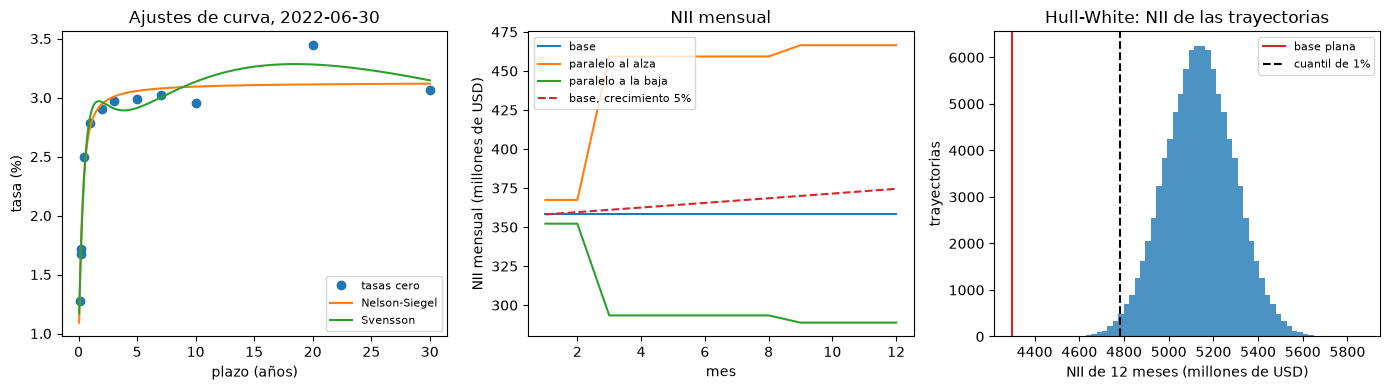

In [13]:
# Dibujar los ajustes de curva, el NII mensual bajo los escenarios y la distribución del NII de 12 meses
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(14, 4))
grid = np.linspace(0.05, 30, 300)
a1.plot(tenors, zero * 100, "o", label="tasas cero")
a1.plot(grid, curves.nelson_siegel_yield(grid, ns.beta0, ns.beta1, ns.beta2, ns.tau) * 100, label="Nelson-Siegel")
a1.plot(grid, curves.svensson_yield(grid, sv.beta0, sv.beta1, sv.beta2, sv.beta3, sv.tau1, sv.tau2) * 100, label="Svensson")
a1.set_xlabel("plazo (años)")
a1.set_ylabel("tasa (%)")
a1.set_title("Ajustes de curva, 2022-06-30")
a1.legend(fontsize=8)
months_axis = np.arange(1, 13)
for key in ("base", "parallel-up", "parallel-down"):
    a2.plot(months_axis, result[key].monthly_nii / 1e3, label=NAME[key])
a2.plot(months_axis, grown.monthly_nii / 1e3, linestyle="--", label="base, crecimiento 5%")
a2.set_xlabel("mes")
a2.set_ylabel("NII mensual (millones de USD)")
a2.set_title("NII mensual")
a2.legend(fontsize=8)
a3.hist(nii_paths / 1e3, bins=60, color="tab:blue", alpha=0.8)
a3.axvline(base_nii / 1e3, color="tab:red", label="base plana")
a3.axvline(np.percentile(nii_paths, 1) / 1e3, color="black", linestyle="--", label="cuantil de 1%")
a3.set_xlabel("NII de 12 meses (millones de USD)")
a3.set_ylabel("trayectorias")
a3.set_title("Hull-White: NII de las trayectorias")
a3.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Resultados

- **Los ajustes de curva.** Nelson-Siegel ajusta las 12 tasas cero del 2022-06-30 con un error de 12,59 pb y Svensson con 10,09 pb, así que la segunda joroba compra 2,5 pb. Ambas fallan el punto de 20 años (3,445 por ciento frente a 3,113 y 3,282 por ciento) y el extremo corto (la tasa a 3 meses 1,716 por ciento frente a 1,883 y 1,842 por ciento). El decaimiento de Nelson-Siegel es 0,25 años, el valor más bajo de su grilla: el mejor ajuste pide un decaimiento más rápido de lo que la grilla permite, así que el resultado depende de la grilla y un validador debe ampliarla antes de confiar en los betas. Una curva ajustada es un modelo de la curva de mercado, no la curva de mercado.
- **Nelson-Siegel dinámico.** La carga de curvatura tiene su máximo en 29,446 meses con el decaimiento de 0,0609, no en los 30 exactos a que redondea el artículo. Los tres factores se mueven a medida que avanza el ciclo de alzas: el nivel sube de 2,07 a 3,10 y a 3,84 por ciento, y el factor de pendiente de -2,09 a -1,27 y a +0,88 por ciento, el paso de una curva ascendente a una invertida. El pronóstico de la celda siguiente sale de un historial construido, así que su dispersión (el nivel a 12 meses entre 2,82 y 3,42 por ciento) muestra cómo funciona la función y no dice nada del banco.
- **El NII mensual.** El NII base de 12 meses es 4.297.741. Con un choque de +200 pb es 5.356.610, una ganancia de 1.058.869; con un choque de -200 pb el piso en cero detiene la tasa corta en 0 por ciento, 128 pb bajo la de hoy, y el NII es 3.620.426, una pérdida de 677.315. Las partidas que reprecian todos los meses se mueven de inmediato, las de 2 meses desde el mes 3 y las de 8 meses desde el mes 9. Cada cifra es igual al escenario versionado. Estos signos son opuestos a los de la brecha de repreciación del cuaderno 01, que dio una pérdida de 199.057 para +100 pb: la brecha trata la parte de los depósitos que ubica a un día como si reprecia con el choque completo, mientras la proyección da a los depósitos con interés un beta de 0,075 y a los sin interés ninguno. El efecto en ganancias de una alza de tasas es entonces tanto una afirmación sobre el beta de depósitos como sobre el balance (el cuaderno 07 compara ambos en las tres fechas).
- **EaR y EVaR.** Con 100.000 trayectorias antitéticas y la semilla versionada, la corrida es igual a la versionada: la EaR es -585.961 al 95 por ciento y -482.023 al 99 por ciento, la EVaR es 3.948.056 y 4.370.301. La EaR es negativa porque todas las trayectorias tienen un NII mayor que la base plana: la tasa corta tiene una media de 2,90 por ciento en el mes 12 (percentiles 5 a 95 de 2,12 a 3,69 por ciento) frente a 1,28 por ciento hoy, pues Hull-White sigue la curva a plazo, y el NII medio de las trayectorias es 5.138.757, 20 por ciento sobre la base. La lectura honesta es que las ganancias no están en riesgo frente a una base que se queda quieta, y que la base es el lado débil de la medida. La EVaR es 4.370.301 al 99 por ciento, 62 por ciento del EVE base de 7.036.780.
- **El error de Monte Carlo.** La EVaR al 99 por ciento es 4.305.713 con 2.000 trayectorias (error 30.669), 4.356.301 con 10.000 (22.474) y 4.370.301 con 100.000 (6.623). El error baja con el número de trayectorias, aunque no de forma suave, porque él mismo se estima con 20 lotes, y las estimaciones quedan a pocos errores de la corrida versionada. Con menos trayectorias la propia estimación de la cola también sería ruidosa: un validador lee el error junto a la estimación, y el motor lo facilita al devolverlo.
- **La verificación fuera de muestra.** Al 2021-12-31 la proyección para +200 pb fue un cambio de -1.138.367 (una ganancia) frente a un cambio realizado de -1.358.000 en 2022: un error relativo de 16,2 por ciento, ámbar. Compara un choque con una trayectoria, así que verifica el orden de magnitud y el signo de la sensibilidad, no el pronóstico. Al 2022-06-30 y al 2022-12-31 no hay año realizado, y la prueba es `not_evaluated` con la razón escrita, nunca un número.
- **Lo que el cuaderno no muestra.** El ajuste del traspaso al historial del banco y la estabilidad de los pesos replicantes (cuaderno 05), la comparación en las tres fechas con las aproximaciones por brecha y por duración (cuaderno 07), y cualquier pronóstico de las tasas reales del banco: el historial de factores es construido.

## Resumen

- Una curva paramétrica comprime una curva de rendimientos en cuatro o seis números; Svensson contiene a Nelson-Siegel y nunca ajusta peor, y el decaimiento de Nelson-Siegel puede quedar en el borde de su grilla.
- El Nelson-Siegel dinámico hace de los tres factores series AR(1) y convierte un historial de factores en escenarios de curvas completas; aquí el historial es construido, porque el historial trimestral del banco no está en el repositorio.
- El NII mensual del balance depende de cuándo reprecia cada partida y del beta de depósitos; el motor reproduce exactamente las proyecciones versionadas, y el balance constante es el supuesto del estándar.
- La EaR y la EVaR son diferencias de cuantiles de trayectorias simuladas, con un error de Monte Carlo que baja con el número de trayectorias; una EaR contra una base plana puede ser negativa cuando los escenarios siguen una curva a plazo ascendente.
- Una proyección se compara con el año realizado cuando existe; el banco no presentó reportes posteriores, así que dos de las tres fechas no lo tienen, y el motor lo dice en vez de devolver un número.

**Qué probar a continuación.** Cambia la reversión a la media `a_hw` y mira cómo la dispersión de la tasa a 12 meses mueve la EVaR más que la EaR. Después sigue con el cuaderno 05, las pruebas de validación.

## Referencias

- Nelson, C. R. y Siegel, A. F. (1987), Parsimonious modeling of yield curves, Journal of Business 60(4). https://doi.org/10.1086/296409
- Svensson, L. E. O. (1994), Estimating and interpreting forward interest rates: Sweden 1992-1994, NBER Working Paper 4871. https://doi.org/10.3386/w4871
- Diebold, F. X. y Li, C. (2006), Forecasting the term structure of government bond yields, Journal of Econometrics 130(2). https://doi.org/10.1016/j.jeconom.2005.03.005
- Hull, J. y White, A. (1990), Pricing interest-rate-derivative securities, Review of Financial Studies 3(4). https://doi.org/10.1093/rfs/3.4.573
- Brigo, D. y Mercurio, F. (2006), Interest Rate Models, Theory and Practice, Springer (ecuación 3.34, según la cita el motor; la edición no está verificada).
- BCBS (2016), d368, Standards: Interest rate risk in the banking book, DIS70.5 (el balance constante). https://www.bis.org/bcbs/publ/d368.htm
- BCBS, Standards: Interest rate risk in the banking book, SRP31. https://www.bis.org/basel_framework/chapter/SRP/31.htm
- FDIC, BankFind financials, dominio público. https://api.fdic.gov/banks/financials
- Departamento del Tesoro de EE. UU., Daily Treasury Par Yield Curve Rates, dominio público. https://home.treasury.gov/resource-center/data-chart-center/interest-rates
- Dossier 05 de la investigación de Contraste, secciones C.4, D.5 y D.6.